<a href="https://colab.research.google.com/github/25031554180-bit/Feature-Engineering/blob/main/AllClustering_Aliya(030)_Restika(180).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Setup Library & Scraping Data Buku

In [135]:
# Install library pendukung
!pip install demoji wordcloud

import requests
from bs4 import BeautifulSoup
import pandas as pd
import re
import demoji
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download('stopwords')

# Scraping data judul buku
root = 'https://books.toscrape.com/catalogue/page-'
titles = []
for page in range(1, 6):
    url = requests.get(root + str(page) + '.html')
    soup = BeautifulSoup(url.text, 'html.parser')
    scrap = soup.find_all('article', {'class': 'product_pod'})
    for i in scrap:
        titles.append(i.find('h3').find('a')['title'])

df = pd.DataFrame({'Title': titles})

# Preprocessing
sw = set(stopwords.words('english'))
ps = PorterStemmer()

def preprocess_text(text):
    text = re.sub(r'<.*?>', '', str(text))
    text = re.sub(r'#\w+', '', text)
    text = text.lower()
    text = re.sub(r'https?://\S+|www\S+|\S+@\S+', '', text)
    text = re.sub(r'[!"#$%&\'()*+,-./:;<=>?@\[\\\]^_`{|}~]', ' ', text)
    text = demoji.replace(text, repl="")
    tokens = text.split()
    tokens = [ps.stem(word) for word in tokens if word not in sw]
    return " ".join(tokens)

df['prepro'] = df['Title'].apply(preprocess_text)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Chapter 8 - Supervised and Unsupervised

In [136]:
import warnings
warnings.filterwarnings("ignore")

from sklearn.feature_extraction.text import TfidfVectorizer

df_pre = df['prepro']
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df_pre)
df_FE = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())

Unsupervised KMeans - Elbow Method (Mencari k Terbaik)

In [137]:
# Unsupervised: KMeans

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from wordcloud import WordCloud

k = range(1, 7)
inertia = []

for i in k:
    km_model = KMeans(n_clusters=i, random_state=10) # jumlah cluster akan di looping
    km_model.fit(df_FE)
    inertia.append(km_model.inertia_)

print(list(k))
print(inertia)

[1, 2, 3, 4, 5, 6]
[98.59592094814465, 96.78607418242822, 95.36592825933754, 94.20464798995532, 92.37553959199303, 90.91174081452449]


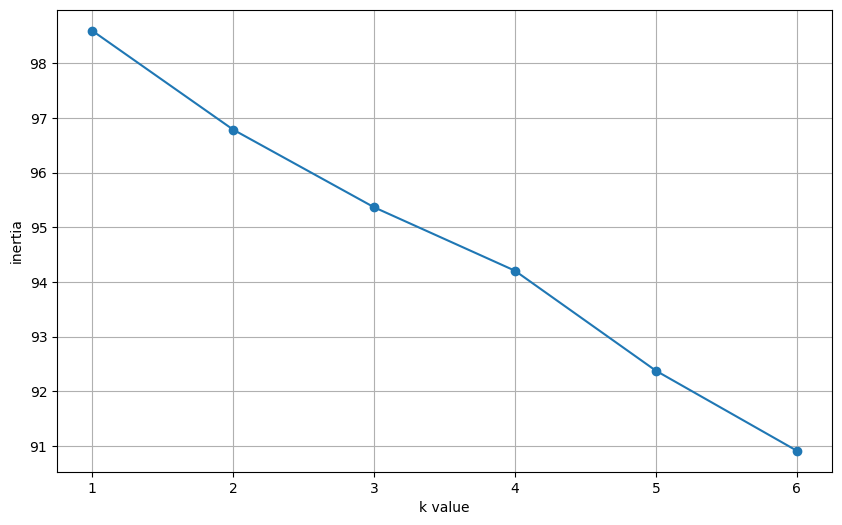

In [138]:
plt.figure(figsize=(10, 6))
plt.plot(k, inertia, marker='o')
plt.xlabel('k value')
plt.ylabel('inertia')
plt.grid()
plt.show()

In [139]:
km = KMeans(n_clusters=4, random_state=10).fit(df_FE)
km

df['Kmeans_label'] = km.labels_
df.head()

,Title,prepro,Kmeans_label
0,A Light in the Attic,light attic,3
1,Tipping the Velvet,tip velvet,3
2,Soumission,soumiss,3
3,Sharp Objects,sharp object,3
4,Sapiens: A Brief History of Humankind,sapien brief histori humankind,3


In [140]:
# Silhouette Score
from sklearn import metrics

labels = km.labels_
metrics.silhouette_score(df_FE, labels, metric='euclidean')

np.float64(0.011460976873478397)

Kmeans for cluster 0


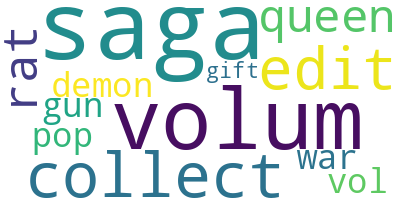

Kmeans for cluster 1


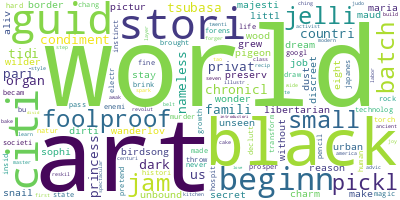

Kmeans for cluster 2


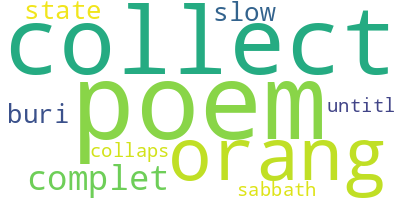

Kmeans for cluster 3


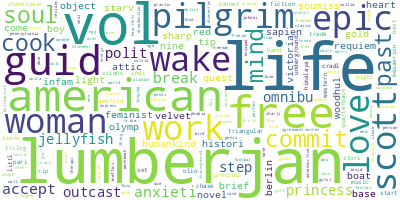

In [141]:
# WordCloud

for x in range(4):
    print(f"Kmeans for cluster {x}")
    df_x = df[df['Kmeans_label'] == x]
    long_string = " ".join(list(df_x['prepro'].values))
    wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=1)
    wordcloud.generate(long_string)
    display(wordcloud.to_image())

hierarchical


In [142]:
from scipy.cluster.hierarchy import dendrogram, linkage

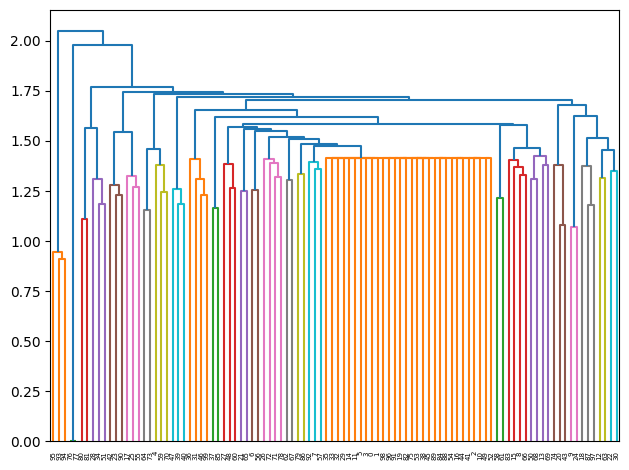

In [143]:
linkage_data = linkage(df_FE, method='ward', metric='euclidean')
dendrogram(linkage_data)
plt.tight_layout()
plt.show()

In [144]:
from sklearn.cluster import AgglomerativeClustering
hierarchical_cluster = AgglomerativeClustering(n_clusters = 4, linkage = 'ward')
labels = hierarchical_cluster.fit(df_FE)

pred_agc = pd.Series(hierarchical_cluster.labels_)
df['Ward_label'] = pred_agc

In [145]:
df.head()

,Title,prepro,Kmeans_label,Ward_label
0,A Light in the Attic,light attic,3,0
1,Tipping the Velvet,tip velvet,3,0
2,Soumission,soumiss,3,0
3,Sharp Objects,sharp object,3,0
4,Sapiens: A Brief History of Humankind,sapien brief histori humankind,3,0


silhoutte

In [146]:
from sklearn import metrics
labels = pred_agc
metrics.silhouette_score(df_FE, labels, metric='euclidean')

np.float64(0.03150151118981946)

word cloud

Hierarchical for cluster 0


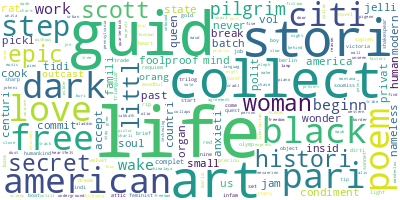

In [147]:
c = 0
print('Hierarchical for cluster '+str(c))
df_c = df[df['Ward_label'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Supervised: Sentiment Analysis

Sentiment positive


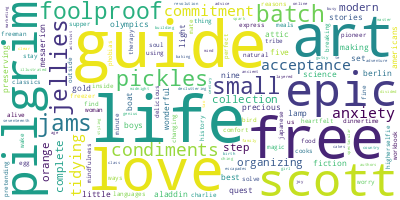

In [148]:
from wordcloud import WordCloud
from textblob import TextBlob

df['text'] = titles
df['prepro'] = df['text'].str.lower()
df['Sentiment'] = df['prepro'].apply(lambda x: 'positive' if TextBlob(x).sentiment.polarity > 0 else 'negative')

c = 'positive'
print('Sentiment '+str(c))
df_c = df[df['Sentiment'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string); wordcloud.to_image()

Sentiment negative


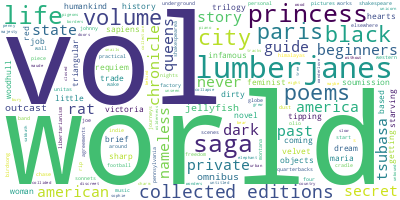

In [149]:
from wordcloud import WordCloud
c = 'negative'
print('Sentiment '+str(c))
df_c = df[df['Sentiment'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string); wordcloud.to_image()

In [150]:
titles = []
for page in range(1, 4):
    url = f"https://books.toscrape.com/catalogue/page-{page}.html"
    response = requests.get(url)
    soup = BeautifulSoup(response.content, "html.parser")
    for h3 in soup.find_all("h3"):
        titles.append(h3.find("a")["title"])
df = pd.DataFrame({'text': titles})
df['prepro'] = df['text'].str.lower()

from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer()
vecs = vectorizer.fit_transform(df_pre)
vecs

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 461 stored elements and shape (100, 381)>

In [151]:
# Mengubah teks menjadi matriks TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer()
vecs = vectorizer.fit_transform(df['prepro'])

In [152]:
# Classify
from textblob import TextBlob
df['Sentiment'] = df['prepro'].apply(lambda x: 'positive' if TextBlob(str(x)).sentiment.polarity >= 0 else 'negative')

X = vecs # FE result
y = df['Sentiment']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

model = RandomForestClassifier()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

[[ 0  3]
 [ 0 15]]
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         3
    positive       0.83      1.00      0.91        15

    accuracy                           0.83        18
   macro avg       0.42      0.50      0.45        18
weighted avg       0.69      0.83      0.76        18



In [155]:
testing = "great story and wonderful adventure"
testing = vectorizer.transform([testing])
testing = model.predict(testing)
print(testing)

['positive']
